The purpose of this Notebook is to answer:

What does "success" actually look like on the Spotify Global Chart?

We will analyze longevity, peak position, Top-10 performances, streaming intensity, performance tiers, hit profiles and artist-independent song performance.

Importantly, this notebook is still descriptive/analytical, not predictive. We will not train ML models here.

### Chart Performance Analytics

### Objective

This notebook performs deeper analysis of Spotify Global Weekly Chart 

The analysis focuses on:

- Chart longevity
- Peak chart position
- Top-10 performance
- Peak streaming performance
- Lifetime streaming performance
- Performance tiers
- Hit profiles
- Longevity versus streaming intensity
- Relationships between different measures of chart success

### Key Questions

1. What defines a high-performing chart song?
2. How does chart longevity relate to total streams?
3. How does peak position relate to streaming performance?
4. Do songs with strong peak performance also have long chart runs?
5. What proportion of songs achieve different levels of chart success?
6. Can songs be grouped into meaningful performances profiles?
7. Are there different types of successful songs?
8. which songs combine strong longevity and streaming performance?

### Important Analytical Note

The variables `wks`, `t10`, `PkStreams` and `total` represent completed chart-performance outcomes.

They are appropriate for descriptive analysis in this notebook.

They should not automatically be used as predictors of one another in a future machine-learning model because doing so can introduce traget leakage.

In [27]:
# Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [28]:
# Project Paths - Since we had path issues, let's use teh absolute Windows path that worked for our project


# ============================================
# 2. PROJECT PATHS
# ============================================

PROJECT_ROOT = Path(
    r"C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_global_chart_totals_lyrics_cleaned.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "chart_performance"
)

TABLE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "chart_performance"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("Figure directory:", OUTPUT_DIR)
print("Table directory:", TABLE_DIR)



Project root: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence
Dataset exists: True
Figure directory: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\outputs\figures\chart_performance
Table directory: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\outputs\tables\chart_performance


In [29]:
# Load processed dataset

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Shape:", df.shape)

Shape: (8058, 29)


In [30]:
display(df.head())

,artist and title,wks,t10,pk,PkStreams,total,artist name,song name,lyrics,peak_duration,artist_song_key,artist_song_key_normalized,wks_outlier,t10_outlier,PkStreams_outlier,total_outlier,extreme_performance_count,log_total,log_wks,log_PkStreams,log_t10,lyrics_original,lyrics_available,lyrics_clean,lyrics_char_count,lyrics_word_count,lyrics_line_count,words_per_line,top10_reached
0,The Weeknd - Blinding Lights,347,64,1,52375259,5441240333,The Weeknd,Blinding Lights,Yeah I've been tryna call I've been on my own ...,13.0,The Weeknd | Blinding Lights,the weeknd | blinding lights,True,True,True,True,4,22.417273,5.852202,17.773945,4.174387,Yeah I've been tryna call I've been on my own ...,True,Yeah I've been tryna call I've been on my own ...,1230,259,1,259.0,1
1,Ed Sheeran - Shape of You,424,34,1,64217796,4470842634,Ed Sheeran,Shape of You,The club isn't the best place to find a lover ...,14.0,Ed Sheeran | Shape of You,ed sheeran | shape of you,True,True,True,True,4,22.220843,6.052089,17.977791,3.555348,The club isn't the best place to find a lover ...,True,The club isn't the best place to find a lover ...,3139,688,1,688.0,1
2,Harry Styles - As It Was,218,60,1,78460903,4417264164,Harry Styles,As It Was,﻿ As It Was - Harry Styles Come on Harry we wa...,11.0,Harry Styles | As It Was,harry styles | as it was,True,True,True,True,4,22.208786,5.389072,18.178111,4.110874,﻿ As It Was - Harry Styles Come on Harry we wa...,True,﻿ As It Was - Harry Styles Come on Harry we wa...,1143,243,1,243.0,1
3,The Neighbourhood - Sweater Weather,333,0,16,21624450,4142643719,The Neighbourhood,Sweater Weather,And all I am is a man I want the world in my h...,NaN,The Neighbourhood | Sweater Weather,the neighbourhood | sweater weather,True,False,False,True,2,22.144600,5.811141,16.889335,NaN,And all I am is a man I want the world in my h...,True,And all I am is a man I want the world in my h...,1678,345,1,345.0,0
4,Lewis Capaldi - Someone You Loved,343,15,4,24962682,3933581891,Lewis Capaldi,Someone You Loved,I'm going under and this time I fear there's n...,NaN,Lewis Capaldi | Someone You Loved,lewis capaldi | someone you loved,True,False,False,True,2,22.092816,5.840642,17.032893,2.772589,I'm going under and this time I fear there's n...,True,I'm going under and this time I fear there's n...,1555,323,1,323.0,1


In [31]:
# Create a dedicated analytics copy - Do not modify the core loaded dataset unnecessarily

analytics_df = df.copy()

print("Analytics dataset shape:", analytics_df.shape)

Analytics dataset shape: (8058, 29)


In [32]:
# Core performance variables

performance_cols = [
    "wks",
    "t10",
    "pk",
    "PkStreams",
    "total"
]

display(
    analytics_df[performance_cols].describe().T
)

,count,mean,std,min,25%,50%,75%,max
wks,8058.0,1.551055e+01,3.092141e+01,1.0,1.00,4.0,1.700000e+01,4.570000e+02
t10,8058.0,8.252668e-01,3.768298e+00,0.0,0.00,0.0,0.000000e+00,7.100000e+01
pk,8058.0,8.366418e+01,6.012591e+01,1.0,30.00,74.0,1.320000e+02,2.460000e+02
PkStreams,8058.0,1.156726e+07,1.025781e+07,166910.0,5368127.50,8941469.5,1.414555e+07,1.288961e+08
total,8058.0,1.419280e+08,3.394366e+08,166910.0,8916825.25,27980926.5,1.188043e+08,5.441240e+09


In [33]:
# Create normalized performance measures- A useful concept in streaming intensity per chart week.

# STREAMING INTENSITY

analytics_df["streams_per_week"] = (
    analytics_df["total"]
    / analytics_df["wks"]
)

analytics_df["peak_streams_per_week"] = (
    analytics_df["PkStreams"]
    / analytics_df["wks"]
)

display(
    analytics_df[
        [
            "wks",
            "total",
            "streams_per_week",
            "peak_streams_per_week"
        ]
    ].describe().T
)


,count,mean,std,min,25%,50%,75%,max
wks,8058.0,1.551055e+01,3.092141e+01,1.00000,1.000000e+00,4.0,1.700000e+01,4.570000e+02
total,8058.0,1.419280e+08,3.394366e+08,166910.00000,8.916825e+06,27980926.5,1.188043e+08,5.441240e+09
streams_per_week,8058.0,7.766864e+06,4.340062e+06,164271.00000,4.878707e+06,7310585.0,1.007203e+07,5.055226e+07
peak_streams_per_week,8058.0,3.293876e+06,3.547284e+06,21223.71519,5.530254e+05,1795068.0,5.150799e+06,2.744558e+07


Two songs can have the same lifetime streams but very different chart histories

For example 
Song A -> high streams accumulated over many weeks
Song B -> high streams concentrated into a shorter period

streams_per_week helps distinguish those patterns.

It is a descriptive metric, not a source-provided Spotify metric.   

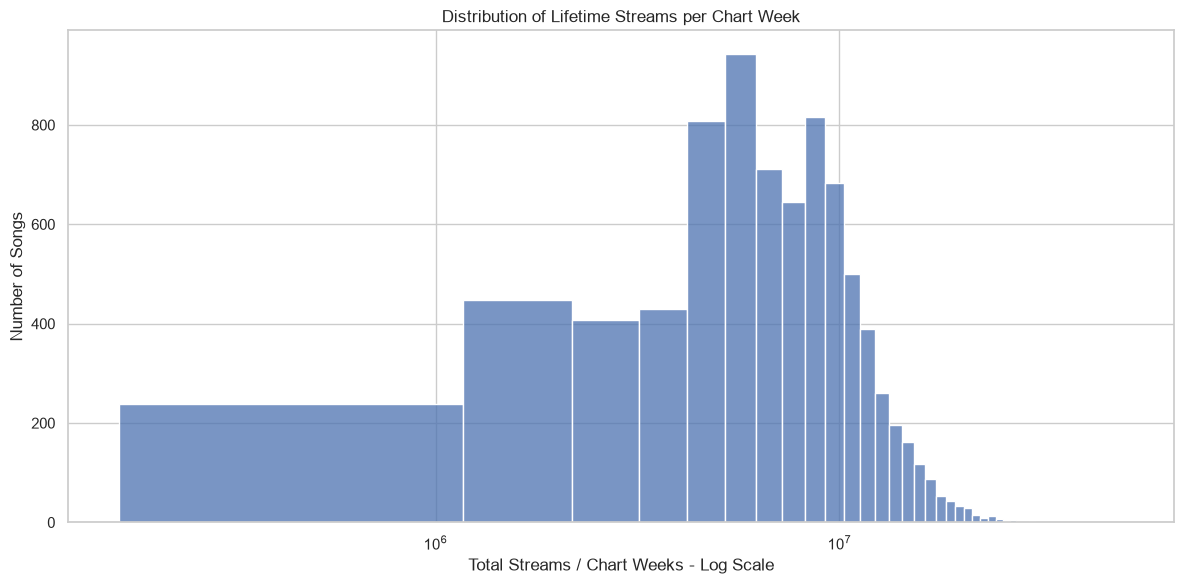

In [34]:
# 8. Distributions of streams per week

# STREAMING INTENSITY DISTRIBUTION

plt.figure(figsize=(12, 6))

sns.histplot(
    data=analytics_df,
    x="streams_per_week",
    bins=50
)

plt.xscale("log")

plt.title(
    "Distribution of Lifetime Streams per Chart Week"
)

plt.xlabel("Total Streams / Chart Weeks - Log Scale")
plt.ylabel("Number of Songs")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "streams_per_week_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


In [35]:
# 9. Chart Longevity categories - We'll use consistent categories throughout this notebook

# LONGEVITY CATEGORIES

def classify_longevity(weeks):

    if weeks <= 4:
        return "Short: 1-4 weeks"

    elif weeks <= 12:
        return "Moderate: 5-12 weeks"

    elif weeks <= 26:
        return "Long: 13-26 weeks"

    elif weeks <= 52:
        return "Very Long: 27-52 weeks"

    else:
        return "Exceptional: 53+ weeks"


analytics_df["longevity_group"] = (
    analytics_df["wks"]
    .apply(classify_longevity)
)

longevity_order = [
    "Short: 1-4 weeks",
    "Moderate: 5-12 weeks",
    "Long: 13-26 weeks",
    "Exceptional: 53+ weeks"
]

display(
    analytics_df["longevity_group"]
    .value_counts()
    .reindex(longevity_order)
)

longevity_group
Short: 1-4 weeks          4080
Moderate: 5-12 weeks      1501
Long: 13-26 weeks         1113
Exceptional: 53+ weeks     562
Name: count, dtype: int64

In [36]:
# 10. Longevity profile

longevity_profile = (
    analytics_df
    .groupby("longevity_group")
    .agg(
        songs=("song name", "count"),
        median_total=("total", "median"),
        median_peak_streams=("PkStreams", "median"),
        median_peak_position=("pk", "median"),
        top10_rate=("top10_reached", "mean")
    )
    .reindex(longevity_order)
)

longevity_profile["top10_rate"] *= 100

display(longevity_profile)

,songs,median_total,median_peak_streams,median_peak_position,top10_rate
longevity_group,,,,,
Short: 1-4 weeks,4080,9188324.5,7275144.5,119.0,0.612745
Moderate: 5-12 weeks,1501,50886147.0,9186131.0,71.0,6.662225
Long: 13-26 weeks,1113,135375171.0,10353406.0,47.0,11.769991
Exceptional: 53+ weeks,562,812214934.0,21399537.5,6.0,60.854093


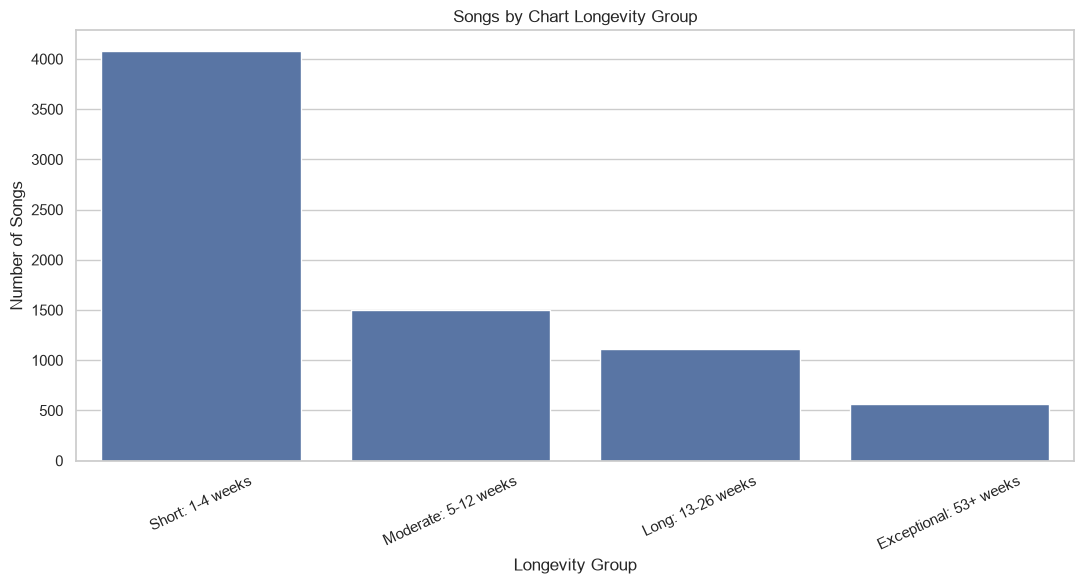

In [37]:
# Visualize longevity profile

plt.figure(figsize=(11, 6))

sns.barplot(
    data=longevity_profile.reset_index(),
    x="longevity_group",
    y="songs"
)

plt.title("Songs by Chart Longevity Group")
plt.xlabel("Longevity Group")
plt.ylabel("Number of Songs")

plt.xticks(rotation=25)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "songs_by_longevity_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [38]:
# 12. Peak-position categories - Instead of treating every peak position separately, create meaningful bands.

# PEAK POSITION GROUPS

def classify_peak(position):

    if position == 1:
        return "Peak #1"

    elif position <= 3:
        return "Top 3"

    elif position <= 5:
        return "Top 5"

    elif position <= 10:
        return "Top 10"

    elif position <= 25:
        return "11-25"

    elif position <= 50:
        return "26-50"

    elif position <= 100:
        return "51-100"

    else:
        return "101+"


analytics_df["peak_group"] = (
    analytics_df["pk"]
    .apply(classify_peak)
)


peak_order = [
    "Peak #1",
    "Top 3",
    "Top 5",
    "Top 10",
    "11-25",
    "26-50",
    "51-100",
    "101+"
]


peak_distribution = (
    analytics_df["peak_group"]
    .value_counts()
    .reindex(peak_order)
)

display(peak_distribution)

peak_group
Peak #1     134
Top 3       200
Top 5       142
Top 10      334
11-25       966
26-50      1239
51-100     1993
101+       3050
Name: count, dtype: int64

In [39]:
# 13. Peak-position performance profile

peak_profile = (
    analytics_df
    .groupby("peak_group")
    .agg(
        songs=("song name", "count"),
        median_weeks=("wks","median"),
        median_total=("total","median"),
        median_peak_streams=("PkStreams", "median"),
        top10_rate = ("top10_reached", "mean")
    )
    .reindex(peak_order)
)

peak_profile["top10_rate"] *= 100

display(peak_profile)

,songs,median_weeks,median_total,median_peak_streams,top10_rate
peak_group,,,,,
Peak #1,134,71.5,991762675.0,44772794.0,100.0
Top 3,200,55.0,574826823.0,33094881.5,100.0
Top 5,142,38.0,422111768.0,28002430.5,100.0
Top 10,334,32.0,313498514.5,23766304.0,100.0
11-25,966,16.5,147606819.0,18393925.5,0.0
26-50,1239,8.0,53040197.0,12513474.0,0.0
51-100,1993,5.0,28649437.0,8462692.0,0.0
101+,3050,1.0,7877313.5,5335289.5,0.0


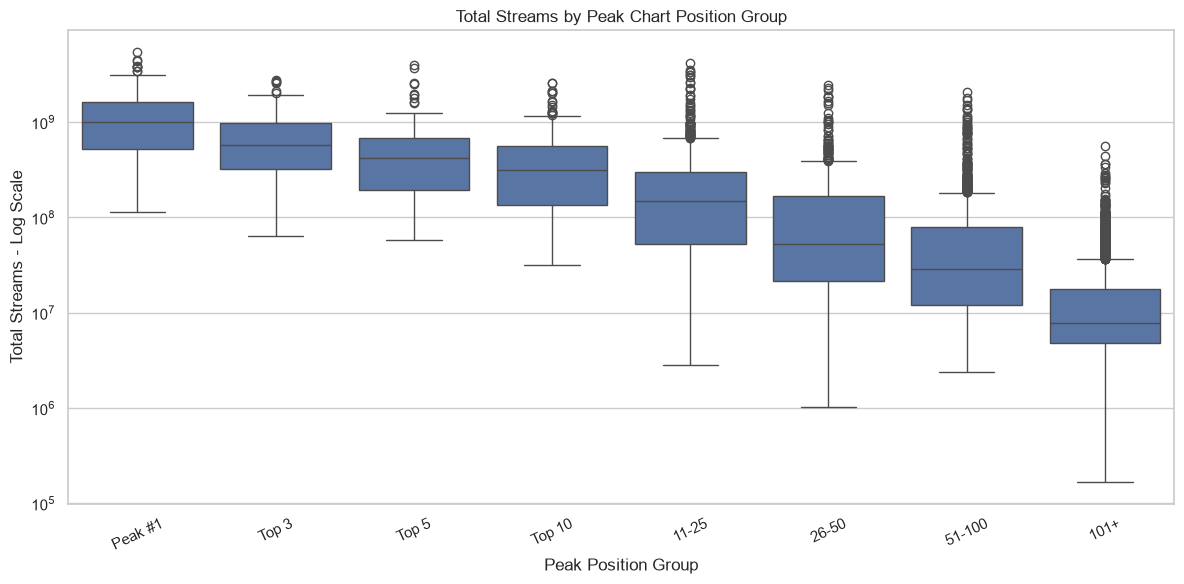

In [40]:
# 14. Peak groups vs total streams

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=analytics_df,
    x="peak_group",
    y="total",
    order=peak_order 
)

plt.yscale("log")

plt.title(
    "Total Streams by Peak Chart Position Group"
)

plt.xlabel("Peak Position Group")
plt.ylabel("Total Streams - Log Scale")

plt.xticks(rotation=25)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "total_streams_by_peak_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [41]:
# 15. Top-10 performance depth - t10 tells us how many Top-10 weeks a song accumulated

# TOP-10 PERFORMANCE 

t10_summary = (
    analytics_df["t10"]
    .describe()
)

display(t10_summary)


count    8058.000000
mean        0.825267
std         3.768298
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        71.000000
Name: t10, dtype: float64

In [42]:
# Categorize

def classify_top10_weeks(t10):

    if t10 == 0:
        return "No Top-10 weeks"

    elif t10 <= 3:
        return "1-3 Top-10 weeks"

    elif t10 <= 10:
        return "4-10 Top-10 weeks"

    elif t10 <= 25:
        return "11-25 Top-10 weeks"

    else:
        return "26+ Top-10 weeks"


analytics_df["top10_depth_group"] = (
    analytics_df["t10"]
    .apply(classify_top10_weeks)
)

top10_depth_order = [
    "No Top-10 weeks",
    "1-3 Top-10 weeks",
    "4-10 Top-10 weeks",
    "11-25 Top-10 weeks",
    "26+ Top-10 weeks"
]

display(
    analytics_df["top10_depth_group"]
    .value_counts()
    .reindex(top10_depth_order)
)

top10_depth_group
No Top-10 weeks       7248
1-3 Top-10 weeks       341
4-10 Top-10 weeks      221
11-25 Top-10 weeks     211
26+ Top-10 weeks        37
Name: count, dtype: int64

In [43]:
# 16. Top-10 depth profile 

top10_depth_profile = (
    analytics_df
    .groupby("top10_depth_group")
    .agg(
        songs=("song name", "count"),
        median_weeks=("wks", "median"),
        median_total=("total", "median"),
        median_pk_streams=("PkStreams", "median")
    )
    .reindex(top10_depth_order)

)


display(top10_depth_profile)

,songs,median_weeks,median_total,median_pk_streams
top10_depth_group,,,,
No Top-10 weeks,7248,3.0,2.192194e+07,8325402.0
1-3 Top-10 weeks,341,19.0,2.163815e+08,27220580.0
4-10 Top-10 weeks,221,44.0,5.087836e+08,27961856.0
11-25 Top-10 weeks,211,73.0,9.119529e+08,31165644.0
26+ Top-10 weeks,37,114.0,2.095527e+09,46995997.0


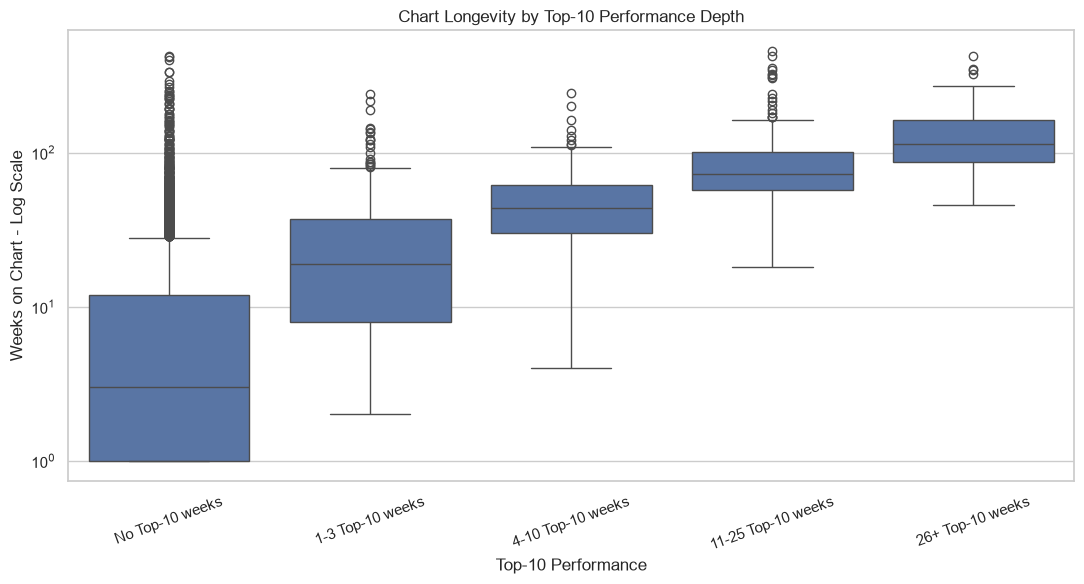

In [44]:
# 17. Top-10 depth vs longevity

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=analytics_df,
    x="top10_depth_group",
    y="wks",
    order=top10_depth_order
)

plt.yscale("log")

plt.title(
    "Chart Longevity by Top-10 Performance Depth"
)

plt.xlabel("Top-10 Performance")
plt.ylabel("Weeks on Chart - Log Scale")

plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "top10_depth_vs_longevity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [45]:
# 18. Identify high-longevity + high-streaming songs 
#  Rather than defining "hit" using only one metric, we can examine songs that are strong on both dimensions.

# First calculate percentile thresholds

# HIGH-PERFORMANCE THRESHOLDS

weeks_threshold = analytics_df["wks"].quantile(0.75)

total_threshold = analytics_df["total"].quantile(0.75)

print(
    f"75th percentile of chart weeks: {weeks_threshold:.2f}"
)

print(
    f"75th percentile of total streams: "
    f"{total_threshold:,.0f}"
)

75th percentile of chart weeks: 17.00
75th percentile of total streams: 118,804,262


In [46]:
# Create the group

analytics_df["high_longevity"] = (
    analytics_df["wks"] >= weeks_threshold
)

analytics_df["high_total_streams"] = (
    analytics_df["total"] >= total_threshold    
)

analytics_df["longevity_streaming_profile"] = np.select(
    [
        analytics_df["high_longevity"]
        & analytics_df["high_total_streams"],

        analytics_df["high_longevity"]
        & ~analytics_df["high_total_streams"],

        ~analytics_df["high_longevity"]
        & analytics_df["high_total_streams"]
    ],
    [
        "High Longevity + High Streams",
        "High Longevity + Lower Streams",
        "Lower Longevity + High Streams"
    ],
    default = "Lower Longevity + Lower Streams"
)

In [47]:
# 19. Performance profile counts 

profile_counts = (
    analytics_df["longevity_streaming_profile"]
    .value_counts()
)

display(profile_counts)

longevity_streaming_profile
Lower Longevity + Lower Streams    5739
High Longevity + High Streams      1747
High Longevity + Lower Streams      304
Lower Longevity + High Streams      268
Name: count, dtype: int64

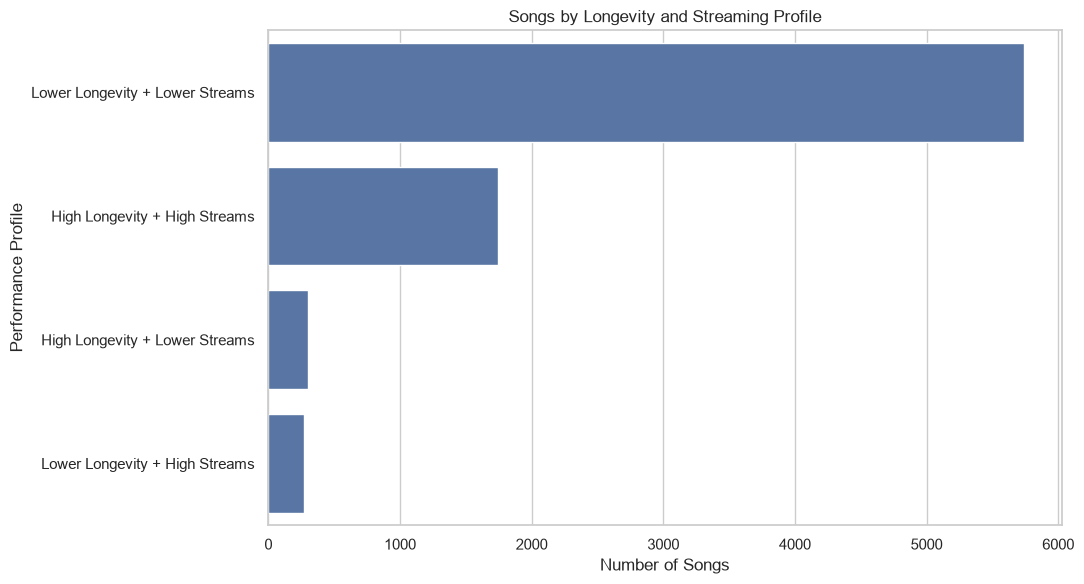

In [48]:
# Visualize 

plt.figure(figsize=(11,6))

sns.barplot(
    x=profile_counts.values,
    y=profile_counts.index
)

plt.title(
    "Songs by Longevity and Streaming Profile"
)

plt.xlabel("Number of Songs")
plt.ylabel("Performance Profile")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "longevity_streaming_profiles.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [49]:
# 20. Inspect the stongest combined performers

# HIGH LONGEVITY + HIGH STREAMING 

combined_hits = (
    analytics_df[
        analytics_df["longevity_streaming_profile"]
        == "High Longevity + High Streams"
    ]
    [
        [
            "artist name",
            "song name",
            "wks",
            "t10",
            "pk",
            "PkStreams",
            "total"
        ]
    ]
    .sort_values(
        "total",
        ascending=False
    )
)

display(
    combined_hits.head(30)
)

,artist name,song name,wks,t10,pk,PkStreams,total
0,The Weeknd,Blinding Lights,347,64,1,52375259,5441240333
1,Ed Sheeran,Shape of You,424,34,1,64217796,4470842634
2,Harry Styles,As It Was,218,60,1,78460903,4417264164
3,The Neighbourhood,Sweater Weather,333,0,16,21624450,4142643719
4,Lewis Capaldi,Someone You Loved,343,15,4,24962682,3933581891
5,The Weeknd,Starboy,317,21,1,35360281,3857210959
6,Billie Eilish,BIRDS OF A FEATHER,114,71,1,66726270,3821072735
7,Lady Gaga,Die With A Smile,101,61,1,78624101,3797546382
8,Post Malone,Sunflower,346,31,1,34579416,3793341693
9,Ed Sheeran,Perfect,457,15,4,24763619,3730229095


This is a useful portfolio table because it identifies songs that are strong according to both longevity and lifetime streaming mesaures


In [50]:
# 21. Compare performance profiles

combined_profile_summary = (
    analytics_df
    .groupby("longevity_streaming_profile")
    .agg(
        songs=("song name", "count"),
        median_weeks=("wks", "median"),
        median_total=("total", "median"),
        median_peak_streams=("PkStreams", "median"),
        median_peak_position=("pk", "median"),
        top10_rate=("top10_reached", "mean")
    )
)

combined_profile_summary["top10_rate"] *= 100 

display(combined_profile_summary)

,songs,median_weeks,median_total,median_peak_streams,median_peak_position,top10_rate
longevity_streaming_profile,,,,,,
High Longevity + High Streams,1747,37.0,332295508.0,15942190.0,17.0,36.004579
High Longevity + Lower Streams,304,21.0,74280630.5,4361914.0,62.0,3.947368
Lower Longevity + High Streams,268,13.0,155272685.5,20918575.0,19.0,32.089552
Lower Longevity + Lower Streams,5739,2.0,14074798.0,7511297.0,103.0,1.446245


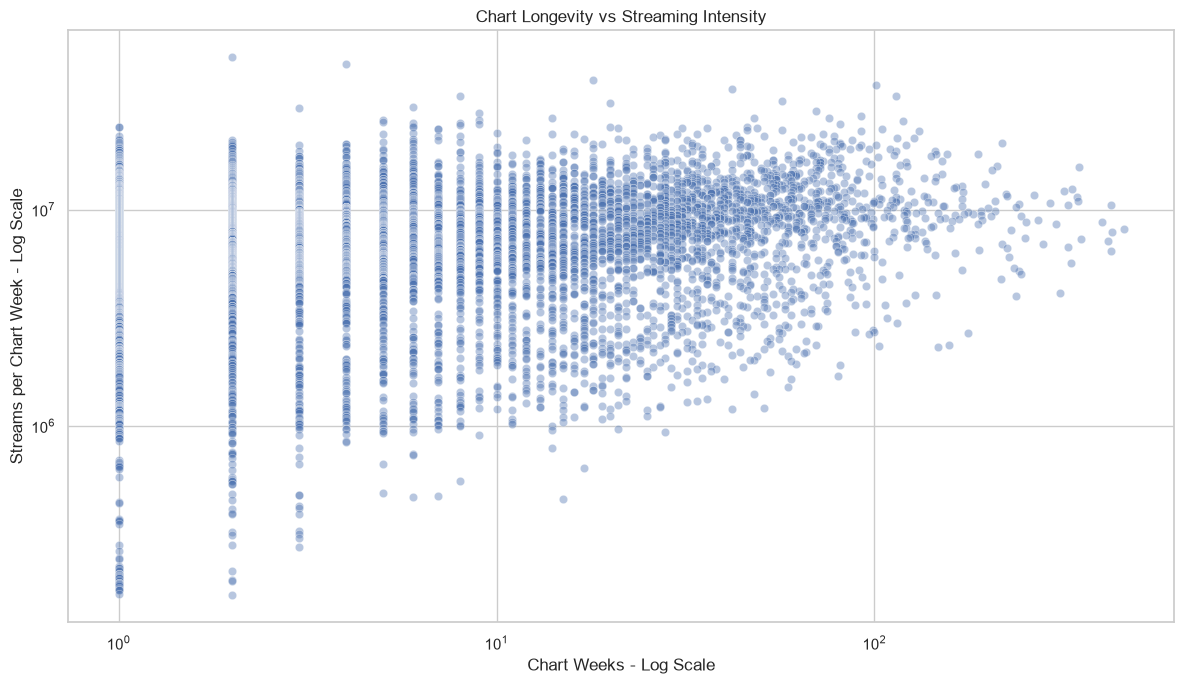

In [51]:
# 22. Streaming intensity vs chart longevity 
# This is an important analytical distinction

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=analytics_df,
    x="wks",
    y="streams_per_week",
    alpha=0.4
)

plt.xscale("log")
plt.yscale("log")

plt.title(
    "Chart Longevity vs Streaming Intensity"
)

plt.xlabel("Chart Weeks - Log Scale")
plt.ylabel("Streams per Chart Week - Log Scale")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "longevity_vs_streaming_intensity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

Interpretation

This can reveal songs that:

1) stay for a long time but have moderate intensity.
2) have huge streaming intensity but shorter chart runs
3) combine both

That is more informative than looking at total alone.

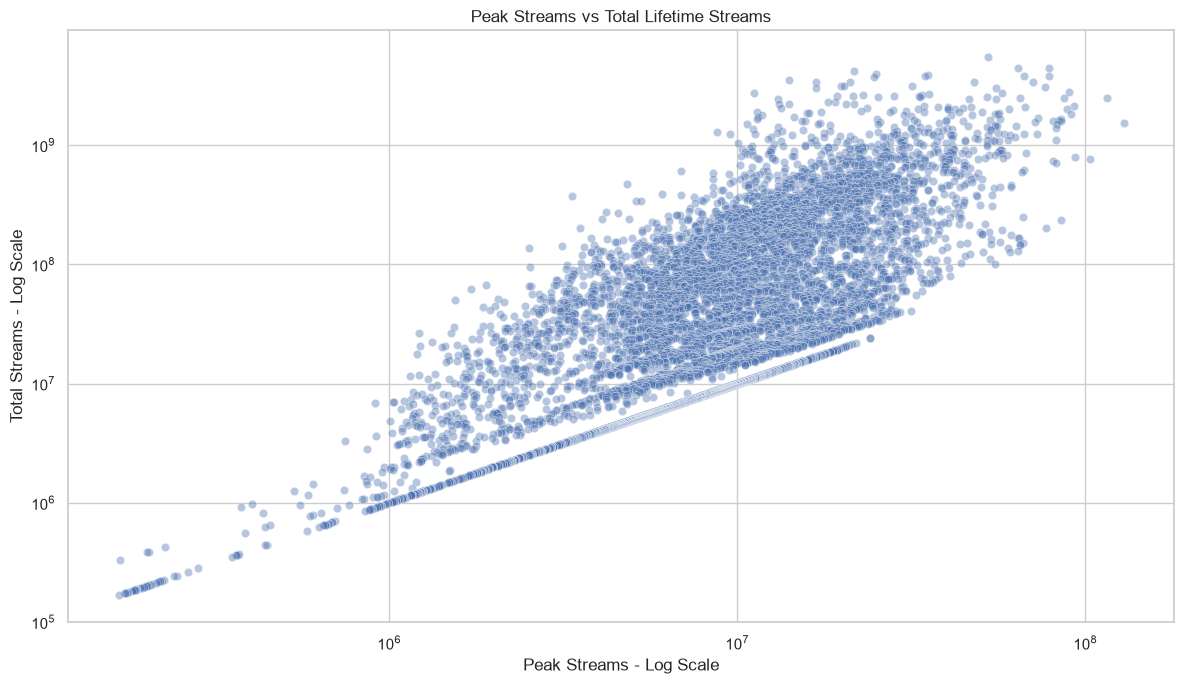

In [53]:
# 23. Peak streams vs total streams

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=analytics_df,
    x="PkStreams",
    y="total",
    alpha=0.4
)

plt.xscale("log")
plt.yscale("log")

plt.title(
    "Peak Streams vs Total Lifetime Streams"
)

plt.xlabel("Peak Streams - Log Scale")
plt.ylabel("Total Streams - Log Scale")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "peak_streams_vs_total.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()
plt.close()

In [54]:
# Calculate the correlation

peak_total_corr = (
    analytics_df[
        ["PkStreams", "total"]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    f"Correlation between peak streams and total streams: "
    f"{peak_total_corr:.3f}"
)

Correlation between peak streams and total streams: 0.589


In [55]:
# 24. Chart performance correlation matrix

# PERFORMANCE CORRELATION MATRIX

analytics_corr_cols = [
    "wks",
    "t10",
    "pk",
    "PkStreams",
    "total",
    "streams_per_week"
]

analytics_corr = (
    analytics_df[analytics_corr_cols]
    .corr()
)

display(analytics_corr)

,wks,t10,pk,PkStreams,total,streams_per_week
wks,1.000000,0.535191,-0.404503,0.383219,0.892997,0.159927
t10,0.535191,1.000000,-0.294015,0.549649,0.700117,0.323723
pk,-0.404503,-0.294015,1.000000,-0.625544,-0.404161,-0.552085
PkStreams,0.383219,0.549649,-0.625544,1.000000,0.588607,0.815841
total,0.892997,0.700117,-0.404161,0.588607,1.000000,0.373855
streams_per_week,0.159927,0.323723,-0.552085,0.815841,0.373855,1.000000


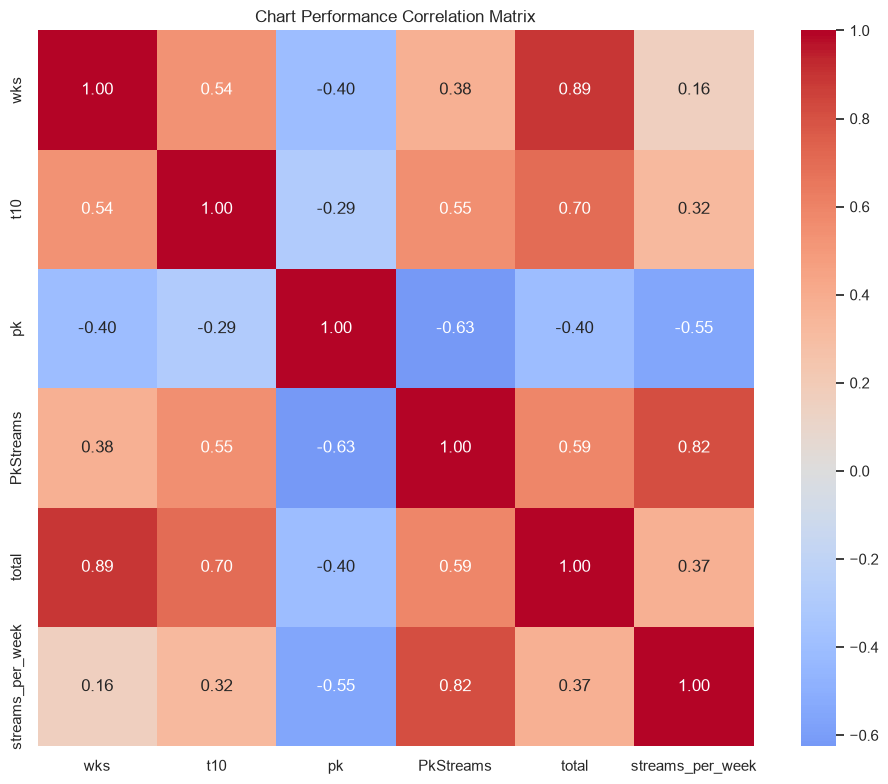

In [56]:
# Visualize

plt.figure(figsize=(10, 8))

sns.heatmap(
    analytics_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Chart Performance Correlation Matrix"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "chart_performance_correlation.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()
plt.close()

In [58]:
# 25. Rank songs using individual performance dimensions 
# Don't create a single "winner" score here. Instead, provide separate analytical rankings.

# Top Longevity

top_longevity = (
    analytics_df[
        [
            "artist name",
            "song name",
            "wks",
            "t10",
            "pk",
            "total"
        ]
    ]
    .sort_values("wks", ascending=False)
    .head(25)
)


display(top_longevity)

,artist name,song name,wks,t10,pk,total
9,Ed Sheeran,Perfect,457,15,4,3730229095
14,Imagine Dragons,Believer,425,0,16,3353483545
1,Ed Sheeran,Shape of You,424,34,1,4470842634
22,OneRepublic,Counting Stars,424,24,3,2739753518
20,Vance Joy,Riptide,415,0,16,2983453847
10,Billie Eilish,lovely,400,0,24,3514154790
30,James Arthur,Say You Won't Let Go,352,15,7,2581216939
0,The Weeknd,Blinding Lights,347,64,1,5441240333
8,Post Malone,Sunflower,346,31,1,3793341693
4,Lewis Capaldi,Someone You Loved,343,15,4,3933581891


In [59]:
# Top lifetime streams

top_total_streams = (
    analytics_df[
        [
            "artist name",
            "song name",
            "wks",
            "t10",
            "pk",
            "total"
        ]
    ]
    .sort_values("total", ascending=False)
    .head(25)
)


display(top_total_streams)

,artist name,song name,wks,t10,pk,total
0,The Weeknd,Blinding Lights,347,64,1,5441240333
1,Ed Sheeran,Shape of You,424,34,1,4470842634
2,Harry Styles,As It Was,218,60,1,4417264164
3,The Neighbourhood,Sweater Weather,333,0,16,4142643719
4,Lewis Capaldi,Someone You Loved,343,15,4,3933581891
5,The Weeknd,Starboy,317,21,1,3857210959
6,Billie Eilish,BIRDS OF A FEATHER,114,71,1,3821072735
7,Lady Gaga,Die With A Smile,101,61,1,3797546382
8,Post Malone,Sunflower,346,31,1,3793341693
9,Ed Sheeran,Perfect,457,15,4,3730229095


In [60]:
# Top peak streams

top_peak_streams = (
    analytics_df[
        [
            "artist name",
            "song name",
            "wks",
            "t10",
            "pk",
            "PkStreams",
            "total"
        ]
    ]
    .sort_values("PkStreams", ascending=False)
    .head(25)
)

display(top_peak_streams)

,artist name,song name,wks,t10,pk,PkStreams,total
104,Taylor Swift,The Fate of Ophelia,42,23,1,128896137,1520442009
36,Miley Cyrus,Flowers,115,25,1,115156896,2459389429
340,Taylor Swift,Fortnight,34,4,1,102878399,757105267
309,Taylor Swift,Opalite,41,8,2,93572415,797146057
47,Mariah Carey,All I Want for Christmas Is You,92,42,1,92506541,2117164649
75,Wham!,Last Christmas,87,34,1,91090914,1815281512
21,Jung Kook,Seven,156,22,1,89748171,2809494264
56,Bad Bunny,DtMF,81,25,1,88786254,2025045584
34,ROSÉ,APT.,92,36,1,87041494,2484667419
1215,Taylor Swift,Elizabeth Taylor,9,3,3,85348366,233721100


This keeps the dimensions separate rather than hiding them inside one arbitrary score.

In [61]:
# 26. Create a chart-performance summary table

# PERFORMANCE SUMMARY 

performance_summary = pd.DataFrame({
    "Metric": [
        "Total songs",
        "Median chart weeks",
        "Mean chart weeks",
        "Median Top-10 weeks",
        "Songs reaching Top 10",
        "Top-10 reach rate (%)",
        "Median peak position",
        "Median peak streams",
        "Median total streams",
        "75th percentile chart weeks",
        "75th percentile total streams"
    ],

    "Value": [
        len(analytics_df),

        analytics_df["wks"].median(),

        analytics_df["wks"].mean(),

        analytics_df["t10"].median(),

        analytics_df["top10_reached"].sum(),

        analytics_df["top10_reached"].mean() * 100,

        analytics_df["pk"].median(),

        analytics_df["PkStreams"].median(),

        analytics_df["total"].median(),

        analytics_df["wks"].quantile(0.75),

        analytics_df["total"].quantile(0.75)
        
    ]
})


display(performance_summary)

,Metric,Value
0,Total songs,8.058000e+03
1,Median chart weeks,4.000000e+00
2,Mean chart weeks,1.551055e+01
3,Median Top-10 weeks,0.000000e+00
4,Songs reaching Top 10,8.100000e+02
5,Top-10 reach rate (%),1.005212e+01
6,Median peak position,7.400000e+01
7,Median peak streams,8.941470e+06
8,Median total streams,2.798093e+07
9,75th percentile chart weeks,1.700000e+01


In [62]:
# 27. Save analytical tables

longevity_profile.to_csv(
    TABLE_DIR / "longevity_profile.csv",
)

peak_profile.to_csv(
    TABLE_DIR / "peak_position_profile.csv"
)

top10_depth_profile.to_csv(
    TABLE_DIR / "top10_depth_profile.csv"
)

combined_profile_summary.to_csv(
    TABLE_DIR / "longevity_streaming_profiles.csv"
)

performance_summary.to_csv(
    TABLE_DIR / "chart_performance_summary.csv",
    index=False
)

combined_hits.to_csv(
    TABLE_DIR / "high_longevity_high_streaming_songs.csv",
    index=False 
)

top_longevity.to_csv(
    TABLE_DIR / "top_longevity_songs.csv",
    index=False 
)


top_total_streams.to_csv(
    TABLE_DIR / "top_total_streaming_songs.csv",
    index=False
)

top_peak_streams.to_csv(
    TABLE_DIR / "top_peak_streaming_songs.csv",
    index=False
)


print("Chart-performance tables saved successfully.")


Chart-performance tables saved successfully.


In [63]:
# 28. Save the enriched analytical dataset.
# We can save this separately from the cleaned dataset.

ANALYTICS_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_chart_performance_analytics.csv"
)

analytics_df.to_csv(
    ANALYTICS_DATA_PATH,
    index=False,
    encoding="utf-8"
)

print("Saved:")
print(ANALYTICS_DATA_PATH)

Saved:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\data\processed\spotify_chart_performance_analytics.csv


In [64]:
# Verify Saved analytics dataset

verify_analytics = pd.read_csv(
    ANALYTICS_DATA_PATH,
    low_memory=False 
)

print(
    "Saved analytics dataset shape:",
    verify_analytics.shape
)

print(
    "File exists:",
    ANALYTICS_DATA_PATH.exists()
)

Saved analytics dataset shape: (8058, 37)
File exists: True


### Final analytical Insights

### Chart Performance Analytics - Key Findings

1. Chart Longevity

Songs exhibit substantial variation in chart longevity. The majority have relatively short chart runs, while a smaller group demonstrates
substantially longer persistence.

2. Streaming Performance

Lifetime total streams are highly concentrated, with a long right tail representing exceptionally successful songs.

3. Top-10 Performance

Reaching the Top 10 represents a distinct level of chart performance. Top 10 depth provides additional information beyond simply whether
a song reached the top 10

4. Peak Position

Peak chart position and peak streaming performance show an inverse association: songs with lower numerical peak positions generally have higher peak streaming levels.

5. Longevity vs Streaming

Longevity and lifetime streams are strongly related, but they represent different dimensions of success.

A song can accumulate high lifetime streams through sustained chart presence, while another may achieve high streaming intensity over a shorter period.

6. Streaming Intensity 

`streams_per_week` provides a descriptive measure for distinguishing sustained chart performance from songs whose streams were concentrated over a shorter chart period.

7. Multi-Dimensional Hit Profiles

Using the 75th percentile of chart weeks and total streams allow songs to be described using separate longevity and streaming dimensions.

This produces profiles such as:

- High Longevity + High Streams
- High Longevity + Lower Streams
- Lower Longevity + High Streams
- Lower Longevity + Lower Streams

These profiles provide a more nuanced view of chart success than a single metric.

8. Analytical Limitation

All performance variables represent completed chart outcomes. Relationships identified here are descriptive associations and should not be interpreted as causal effects.

9. Next Stage

The next notebooks will investigate:

- artist-level performance
- lyrical characteristics
- NLP features
- song segmentation
- predictive modeling
- and model explainability
